In [3]:
import pandas as pd

df = pd.read_csv("high_diamond_ranked_10min.csv")
print(df.shape)   # (行数, 列数) が出る。(9879, 40) ならOK
df.head()         # 最初の5行を表示

(9879, 40)


,gameId,blueWins,blueWardsPlaced,blueWardsDestroyed,blueFirstBlood,blueKills,blueDeaths,blueAssists,blueEliteMonsters,blueDragons,...,redTowersDestroyed,redTotalGold,redAvgLevel,redTotalExperience,redTotalMinionsKilled,redTotalJungleMinionsKilled,redGoldDiff,redExperienceDiff,redCSPerMin,redGoldPerMin
0,4519157822,0,28,2,1,9,6,11,0,0,...,0,16567,6.8,17047,197,55,-643,8,19.7,1656.7
1,4523371949,0,12,1,0,5,5,5,0,0,...,1,17620,6.8,17438,240,52,2908,1173,24.0,1762.0
2,4521474530,0,15,0,0,7,11,4,1,1,...,0,17285,6.8,17254,203,28,1172,1033,20.3,1728.5
3,4524384067,0,43,1,0,4,5,5,1,0,...,0,16478,7.0,17961,235,47,1321,7,23.5,1647.8
4,4436033771,0,75,4,0,6,6,6,0,0,...,0,17404,7.0,18313,225,67,1004,-230,22.5,1740.4


In [4]:
df["blueWins"].mean()   # 青チームの勝率。0.5前後なら偏りがないデータ

np.float64(0.4990383642069035)

In [5]:
cols = ["blueGoldDiff", "blueKills", "blueDeaths", "blueDragons", "blueHeralds", "blueWardsPlaced"]
df.groupby("blueWins")[cols].mean()

,blueGoldDiff,blueKills,blueDeaths,blueDragons,blueHeralds,blueWardsPlaced
blueWins,,,,,,
0,-1237.066680,5.170135,7.131138,0.259446,0.151950,22.286725
1,1270.718053,7.201623,5.140365,0.464909,0.224138,22.289858


In [6]:
df.groupby("blueFirstBlood")["blueWins"].mean()

,blueWins
blueFirstBlood,
0,0.397179
1,0.598957


In [7]:
print(df.groupby("blueDragons")["blueWins"].mean())
print(df.groupby("blueHeralds")["blueWins"].mean())

blueDragons
0    0.418531
1    0.640940
Name: blueWins, dtype: float64
blueHeralds
0    0.476814
1    0.595046
Name: blueWins, dtype: float64


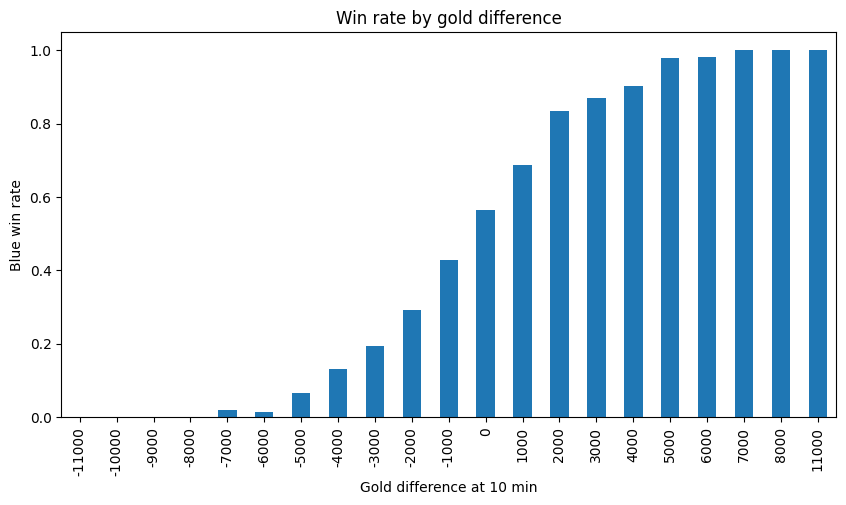

In [8]:
import matplotlib.pyplot as plt

# ゴールド差を1000ごとの区間に分けて、区間ごとの勝率を出す
df["goldBin"] = (df["blueGoldDiff"] // 1000) * 1000
win_rate = df.groupby("goldBin")["blueWins"].mean()

win_rate.plot(kind="bar", figsize=(10, 5))
plt.xlabel("Gold difference at 10 min")
plt.ylabel("Blue win rate")
plt.title("Win rate by gold difference")
plt.show()

In [9]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

X = df[cols + ["blueFirstBlood"]]   # 予測に使う情報
y = df["blueWins"]                  # 当てたい答え

# 8割で学習、2割でテスト
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
print("正解率:", model.score(X_test, y_test))

正解率: 0.7181174089068826


In [10]:
cols = ["blueTotalMinionsKilled","blueAvgLevel","blueWardsDestroyed"]
df.groupby("blueWins")[cols].mean()

,blueTotalMinionsKilled,blueAvgLevel,blueWardsDestroyed
blueWins,,,
0,211.793090,6.807032,2.728834
1,221.624949,7.025396,2.921298


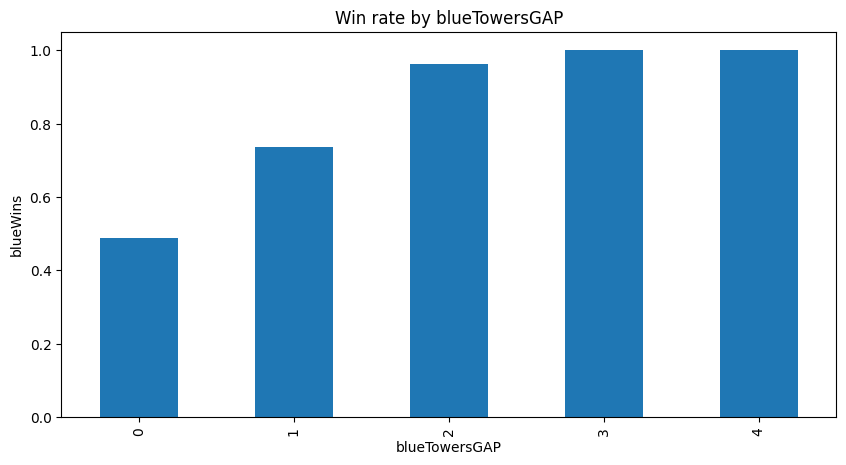

In [11]:
import matplotlib.pyplot as plt
df['blueTowersGAP']=(df['blueTowersDestroyed'])
win_rate=df.groupby("blueTowersGAP")["blueWins"].mean()
win_rate.plot(kind="bar",figsize=(10,5))
plt.xlabel("blueTowersGAP")
plt.ylabel("blueWins")
plt.title("Win rate by blueTowersGAP")
plt.show()

In [12]:
df["blueTowersGAP"].value_counts()

,count
blueTowersGAP,
0,9415
1,429
2,27
3,7
4,1


In [14]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

# リスト内の文字列を引き算するのではなく、カンマで区切って特徴量として追加します
X = df[cols + ["blueKills", "blueDeaths"]]
y = df["blueWins"]                  # 当てたい答え

# 8割で学習、2割でテスト
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
print("正解率:", model.score(X_test, y_test))

正解率: 0.7019230769230769


In [15]:
# 1. 青チームのキル数とデス数の差分を計算して新しい列を作成します
df["blueKillsMinusDeaths"] = df["blueKills"] - df["blueDeaths"]

# 2. 特徴量（予測に使う情報）として設定
X = df[cols + ["blueKillsMinusDeaths"]]
y = df["blueWins"]                  # 当てたい答え

# 3. データを学習用（8割）とテスト用（2割）に分割
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

# 4. モデルの学習と予測精度の算出
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)
print("正解率:", model.score(X_test, y_test))

正解率: 0.7019230769230769


In [20]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

# リスト内の文字列を引き算するのではなく、カンマで区切って特徴量として追加します
features = ["blueGoldDiff", "blueKills", "blueDeaths", "blueDragons",
            "blueHeralds", "blueWardsPlaced", "blueFirstBlood",
            "blueTotalMinionsKilled", "blueAvgLevel", "blueWardsDestroyed"]
X = df[features]
y = df["blueWins"]                  # 当てたい答え

# 8割で学習、2割でテスト
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

model = LogisticRegression(max_iter=100000)
model.fit(X_train, y_train)
print("正解率:", model.score(X_test, y_test))

正解率: 0.7171052631578947


In [21]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression

# リスト内の文字列を引き算するのではなく、カンマで区切って特徴量として追加します
features = ["blueGoldDiff"]
X = df[features]
y = df["blueWins"]                  # 当てたい答え

# 8割で学習、2割でテスト
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

model = LogisticRegression(max_iter=100000)
model.fit(X_train, y_train)
print("正解率:", model.score(X_test, y_test))

正解率: 0.7125506072874493


In [18]:
print(cols)

['blueTotalMinionsKilled', 'blueAvgLevel', 'blueWardsDestroyed']


# League of Legends: What Decides the Game in the First 10 Minutes?

## Overview
Using about 10,000 Diamond-ranked solo queue games, I analyzed which early-game factors (first 10 minutes) are related to winning, and built a simple model to predict the match outcome.

## Data
[League of Legends Diamond Ranked Games (10 min)](https://www.kaggle.com/datasets/bobbyscience/league-of-legends-diamond-ranked-games-10-min) on Kaggle
- 9,879 games, 40 columns
- Target: `blueWins` (1 = blue team won, 0 = lost)
- Blue team win rate is 49.9%, so the data is balanced

## Key Findings
1. **Gold difference is the strongest signal.**
   In games the blue team won, it was ahead by about +1,270 gold at 10 minutes on average. In games it lost, it was behind by about -1,240.

2. **Objectives matter, especially dragons.**
   - First Blood: win rate 59.9% (taken) vs 39.7% (not taken)
   - Dragon: 64.1% vs 41.9% (+22 points)
   - Rift Herald: 59.5% vs 47.7% (+12 points)

3. **Destroying a tower early is a strong sign of winning.**
   Teams that destroyed 1 tower by 10 minutes won about 75% of the time (429 games). Games with 2+ towers had very high win rates, but there were only 35 such games, so I did not draw conclusions from them.

4. **The number of wards placed has almost no relation to winning.**
   Both winning and losing games averaged about 22.3 wards. However, this data cannot measure *where* or *when* wards were placed, which may still matter.

5. **The model predicts about 72% of games correctly.**
   A logistic regression model reached 71.8% accuracy on the test data, compared to about 50% for random guessing. Adding more features (CS, level, kill difference) did not improve accuracy, likely because that information is already included in gold difference.

## Limitations
- These results show correlation, not causation. For example, stronger teams may get First Blood *and* win, rather than First Blood causing the win.
- Only the first 10 minutes are included, so about 28% of games are comeback cases the model cannot predict.

## What I Learned
- Always compare results to a baseline (50% for random guessing)
- Be careful with small groups: a 100% win rate from 1 game means nothing
- Adding features only helps if they contain new information

## Tools
Python, pandas, matplotlib, scikit-learn, Google Colab, and generative AI (Claude, Gemini) for coding support